# Optimizing document review agents for cost and quality: decision models vs LLMs

An e-discovery agent reviews each page: **produce**, **withhold**, **redact** or send to an **attorney**.

**Goal:** cut cost and latency without losing quality, and find which steps need an LLM and which only need a decision model.

In [1]:
%matplotlib inline
import os

import pandas as pd
from dotenv import load_dotenv
from IPython.display import display
from openai import AsyncOpenAI

load_dotenv(override=False)
RUN_LIVE_API_CALLS = os.environ.get("RUN_LIVE_API_CALLS", "false").lower() == "true"
LANGSMITH_TRACING = os.environ.get("LANGSMITH_TRACING", "false").lower() == "true"
if RUN_LIVE_API_CALLS and not os.environ.get("OPENAI_API_KEY"):
    raise RuntimeError("Set OPENAI_API_KEY before enabling live API calls.")
if LANGSMITH_TRACING and not os.environ.get("LANGSMITH_API_KEY"):
    raise RuntimeError("Set LANGSMITH_API_KEY before enabling LangSmith tracing.")
os.environ["LANGSMITH_TRACING"] = str(LANGSMITH_TRACING).lower()
os.environ["LANGCHAIN_TRACING_V2"] = str(LANGSMITH_TRACING).lower()
os.environ.setdefault("LANGSMITH_PROJECT", "doc-review-opt")
from doc_review_opt.config import get_settings
from doc_review_opt.experiment.live import BudgetTracker
from doc_review_opt.reporting.diagrams import draw_diagram
LIVE = get_settings().live
client = AsyncOpenAI(timeout=LIVE.timeout_s, max_retries=LIVE.max_retries) if RUN_LIVE_API_CALLS else None
budget = BudgetTracker()
print(f"Live: {RUN_LIVE_API_CALLS} | LangSmith: {LANGSMITH_TRACING} | budget stop: ${budget.limit_usd:.2f}")

Live: False | LangSmith: False | budget stop: $1.00


| Step | Section | Time |
|---|---|---|
| The agent | Business rules, the LangGraph graph, one run | 4 min |
| Version 1 | Success criteria, eval set, baseline | 3 min |
| Traces → find errors | Measure the baseline | 3 min |
| Tune → climb | Rounds 1 to 5, one lever each | 12 min |
| Tradeoffs | LLM vs Decisions | (in Round 3) |
| Check | Results, live reality check, takeaways | 5 min |

## The agent

**The business.** In a lawsuit, Arcadia Freight must hand the other side every relevant page. Each page gets exactly one outcome:

| The page is… | Outcome | Why it matters |
|---|---|---|
| Lawyer–client advice (privileged) | **attorney review**, then withhold | Producing it can waive privilege |
| Not relevant to the case | **withhold** | Nothing to hand over |
| Relevant, with personal data | **redact**, then produce | Personal data must not leak |
| Relevant and clean | **produce** | |
| Unclear | **attorney review** | Safe, but $1.50 of attorney time |

In [2]:
from doc_review_opt.fixtures import EVAL_SET
from doc_review_opt.reporting.walkthrough import page_table

OUTCOMES = ("produce", "withhold", "redact", "attorney_review")
demo_pages = [next(p for p in EVAL_SET if p.labels.expected_route == o) for o in OUTCOMES]
display(page_table(demo_pages).style.hide(axis="index"))

doc_id,page,from,expected
ARC-000141,Q3 2024 REVENUE SUMMARY (INTERNAL),Finance Reporting,produce
ARC-000212,FACILITIES NOTICE,Ines Calloway,withhold
ARC-000352,SALES OPS EMAIL,Noor Haddad,redact
ARC-000284,EMAIL,Priya Raghunathan (attorney),attorney_review


## How the agent works: one LangGraph graph

- `Send` fans the batch out: one `review_page` subgraph per page, run in parallel.
- `classify` runs the engine. In Version 1 the agent's own answer picks the end node; from Round 3, plain code (`decide`) picks it from typed answers.
- `attorney_review` pauses the graph with `interrupt()` until an attorney answers. `redact` jumps there only if redaction fails; LangGraph's drawing leaves out its normal exit.

Dashed arrows are conditional. Every round keeps this graph; only what runs inside the nodes changes. Version 1's engine is one `gpt-6.1-terra` agent with five tools.

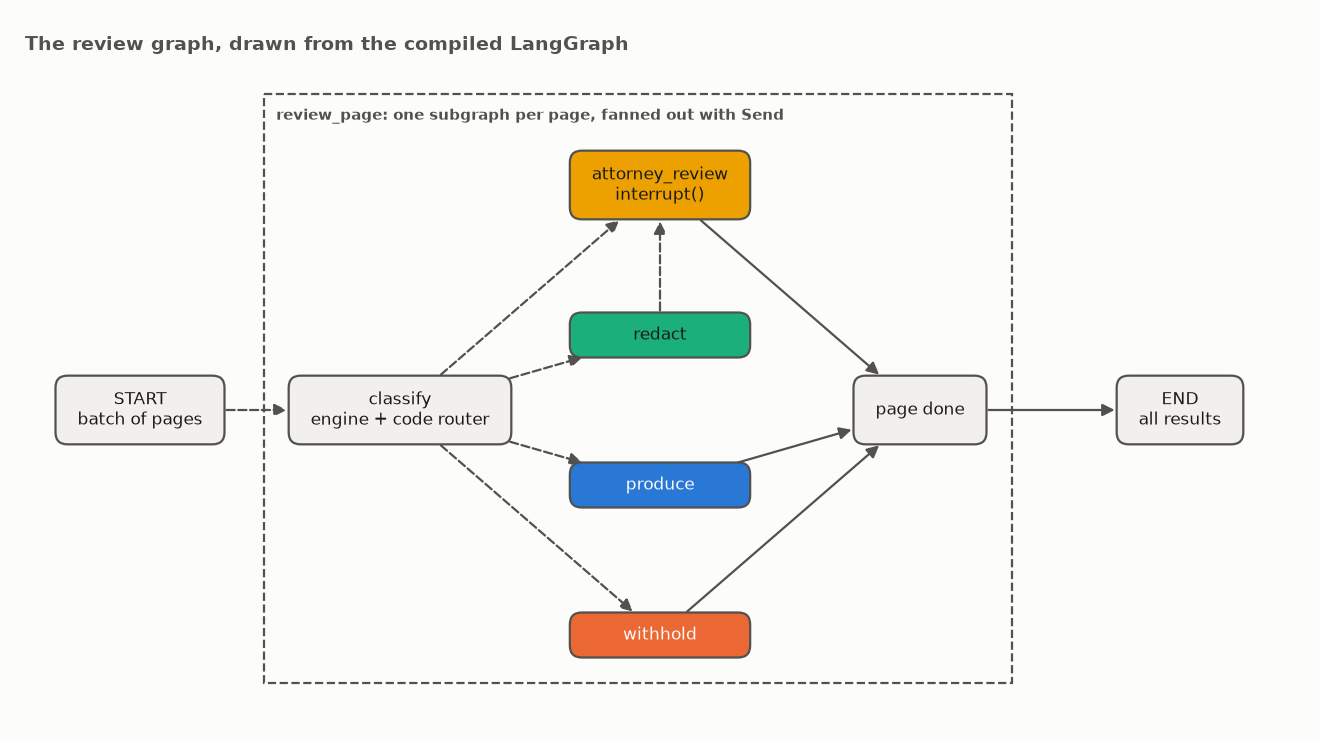

In [3]:
from doc_review_opt.agent.graph import build_review_graph, review_checkpointer
from doc_review_opt.agent.variants import BASELINE, VARIANTS, default_policy
from doc_review_opt.experiment.simulation import build_simulated_engines
from doc_review_opt.reporting.diagrams import draw_graph

policy = default_policy(VARIANTS[BASELINE])
engine, redactor = build_simulated_engines(VARIANTS[BASELINE], EVAL_SET, policy)
review_graph = build_review_graph(engine, redactor, review_checkpointer(), policy=policy)
draw_graph(review_graph.get_graph(xray=True))

### One run: four pages through Version 1

The privileged page stops at `attorney_review`. The pause carries the page id and the reason, never page text.

In [4]:
from uuid import uuid4

config = {"configurable": {"thread_id": f"intro-{uuid4()}"}}
paused = await review_graph.ainvoke({"pages": demo_pages, "results": []}, config)
waiting = [pending.value["doc_id"] for pending in paused["__interrupt__"]]
print(f"{len(paused['results'])} pages finished, {len(waiting)} waiting for an attorney: {', '.join(waiting)}")

3 pages finished, 1 waiting for an attorney: ARC-000284


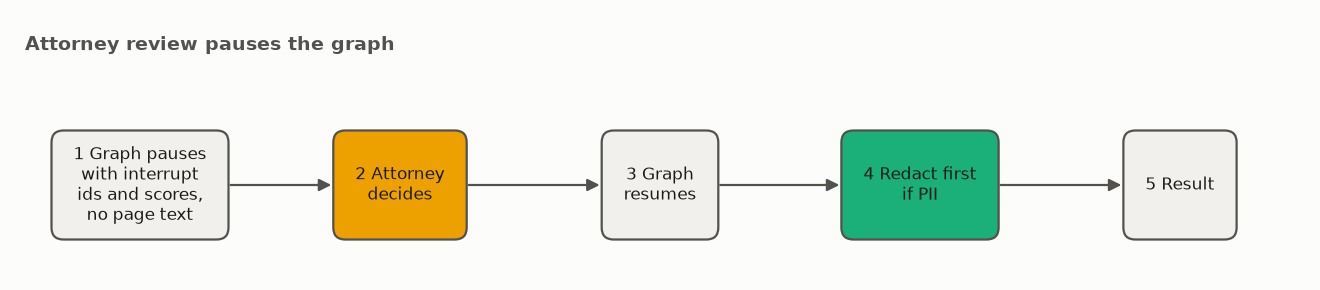

In [5]:
draw_diagram("human_in_the_loop")

In [6]:
from langgraph.types import Command

resume = {pending.id: "withhold" for pending in paused["__interrupt__"]}
final = await review_graph.ainvoke(Command(resume=resume), config)
display(page_table(demo_pages, final["results"]).style.hide(axis="index"))

doc_id,page,from,expected,route,decision
ARC-000141,Q3 2024 REVENUE SUMMARY (INTERNAL),Finance Reporting,produce,produce,produce
ARC-000212,FACILITIES NOTICE,Ines Calloway,withhold,withhold,withhold
ARC-000352,SALES OPS EMAIL,Noor Haddad,redact,redact,produce
ARC-000284,EMAIL,Priya Raghunathan (attorney),attorney_review,attorney_review,withhold


## The optimization loop

Version 1 handles these four pages. Is it cheap, fast and safe on all 30? Measure, find errors, change one lever, measure again.

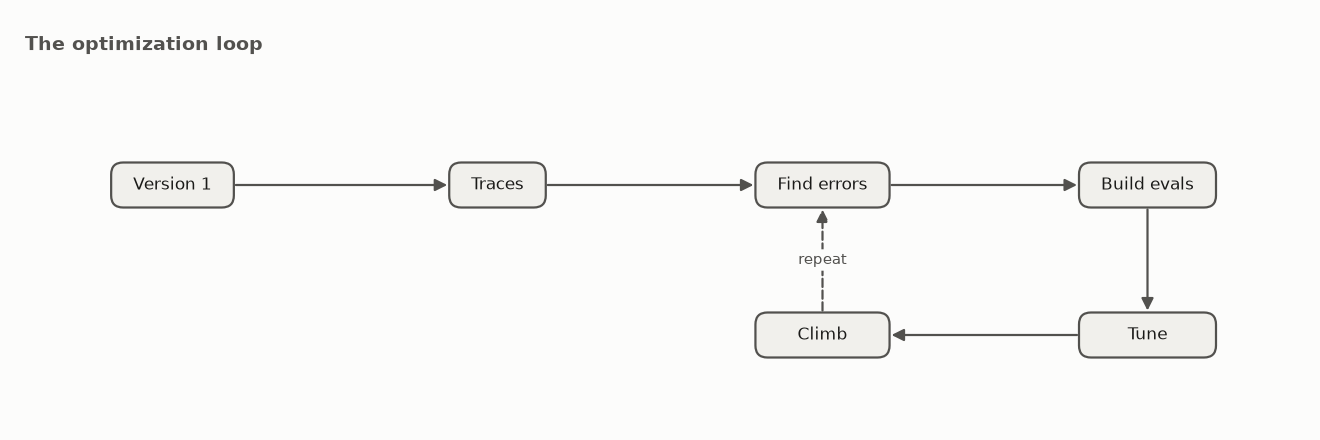

In [7]:
draw_diagram("optimization_loop")

## Success criteria

- **Hard gates:** zero privileged pages produced, zero PII left in produced text.
- **Accept a round** only if at least 95% of pages pass the guardrails.
- **Cost** = model cost + attorney time ($1.50 per escalated page).

## Eval set

30 synthetic, labelled pages for one matter; 10 are traps or borderline.

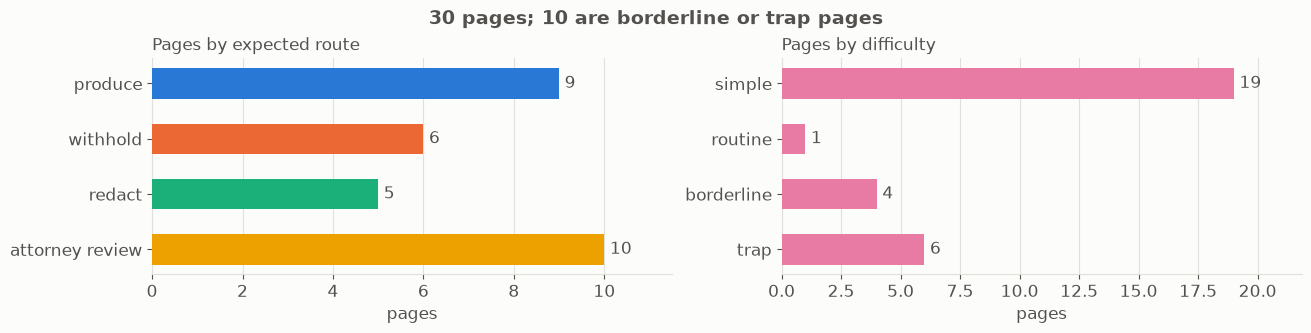

In [8]:
from doc_review_opt.fixtures import EVAL_SET
from doc_review_opt.reporting.reporting import plot_eval_set

eval_table = pd.DataFrame(
    {
        "doc_id": page.doc_id,
        "expected_route": page.labels.expected_route,
        "difficulty": page.labels.difficulty,
    }
    for page in EVAL_SET
)
display(plot_eval_set(eval_table))

## Version 1: the bad baseline

One `gpt-6.1-terra` super-agent: every tool on every page, verbose payloads, free-text answer.

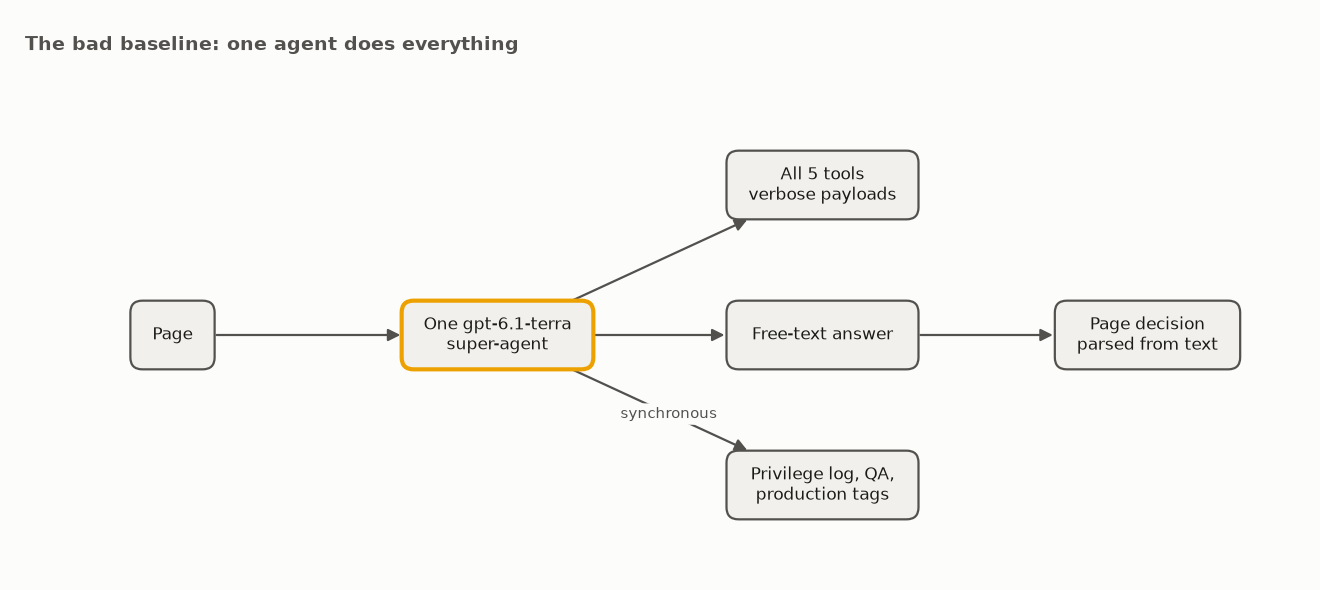

In [9]:
draw_diagram("bad_baseline")

## Measure: traces, then errors

Every round runs on all 30 pages (simulated, seconds). One trace per page per round.

In [10]:
from doc_review_opt.agent.variants import (
    BASELINE,
    CACHING,
    CALIBRATED_POLICY,
    CONTROLS,
    DECISION_MODEL,
    ROUTING,
    SPLIT,
    VARIANT_ORDER,
)

In [11]:
from doc_review_opt.experiment.simulation import simulate_all
from doc_review_opt.experiment.traces import traces_frame
from doc_review_opt.reporting.reporting import plot_progress, summarize
from doc_review_opt.reporting.walkthrough import before_after, gate, request_diff, symptoms

traces = await simulate_all()
frame = traces_frame(traces)
summary = summarize(frame)
SAMPLE_PAGE = next(p for p in EVAL_SET if p.labels.privileged)
LOW_PAGE = next(p for p in EVAL_SET if p.labels.risk == "low" and not p.labels.privileged)

In [12]:
columns = ["variant_label", "doc_id", "route", "tool_calls", "sync_tokens", "latency_s", "model_cost_usd", "quality_score"]
formats = {"sync_tokens": "{:,.0f}", "latency_s": "{:.2f}", "model_cost_usd": "${:.5f}", "quality_score": "{:.2f}"}
display(frame[columns].head().style.format(formats).hide(axis="index"))

variant_label,doc_id,route,tool_calls,sync_tokens,latency_s,model_cost_usd,quality_score
Bad baseline,ARC-000141,produce,5,"6,491",3.18,$0.00701,0.85
Bad baseline,ARC-000163,attorney_review,5,"8,886",4.11,$0.00926,0.36
Bad baseline,ARC-000212,withhold,5,"8,624",3.59,$0.00915,0.85
Bad baseline,ARC-000245,withhold,5,"8,628",3.59,$0.00915,0.85
Bad baseline,ARC-000259,withhold,5,"8,617",3.59,$0.00914,0.85


In [13]:
print(symptoms(summary, BASELINE))
print(gate(traces, BASELINE))

Bad baseline
  tool calls: 5.0 per page (4.2 unneeded)
  sync tokens: 8,287 per page
  p50 latency: 3.59s
  model cost: $0.00879 per page
  escalation rate: 50%
  leaks: privileged 0, PII 2
Bad baseline: REJECTED (guardrail pass 0%, floor 95%; failures: too_many_unnecessary_tools=30, escalation_mismatch=5, unnecessary_attorney_review=5, unparseable_agent_output=1, pii_in_produced_text=2)


**Errors found:** 4.2 of 5 tool calls per page are unneeded, about 8k tokens per page, PII left in produced text on 2 pages. Each round fixes one thing.

## Round 1: prompt, tool and context controls

**Lever:** tight prompt, allow-listed tools, slim payloads, strict JSON answer.

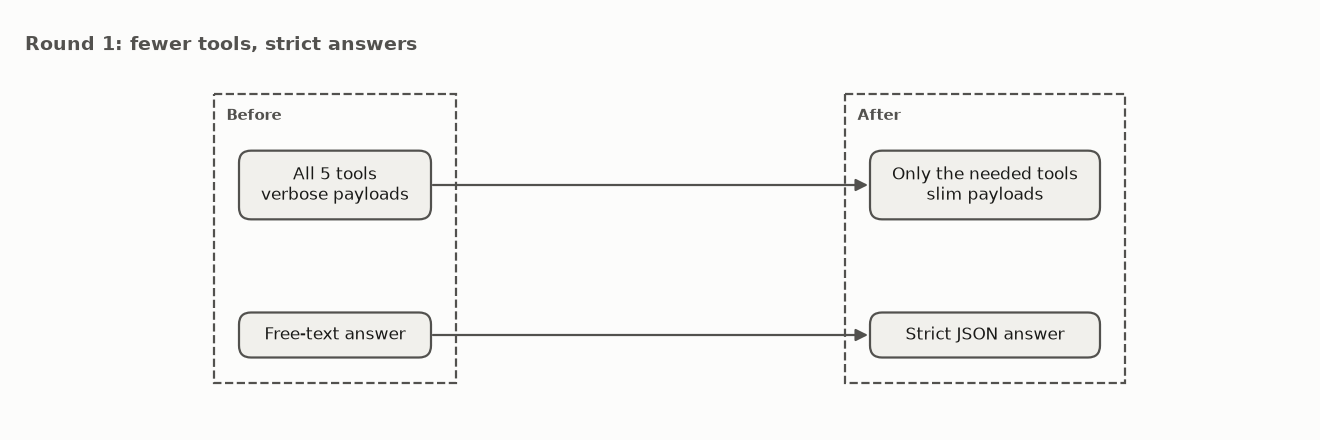

In [14]:
draw_diagram("round1")

In [15]:
display(request_diff(BASELINE, CONTROLS, SAMPLE_PAGE).style.hide(axis="index"))

setting,before,after
verbosity,high,low
structured_output,free text,review_disposition
max_output_tokens,1200,600
tool_choice,required,"{""type"": ""allowed_tools"", ""mode"": ""auto"", ""tools"": [{""type"": ""function"", ""name"": ""lookup_custodian""}, {""type"": ""function"", ""name"": ""escalate_to_attorney""}]}"
instructions_chars,851,841
input_chars,529,416


metric,before,after
quality,0.76,0.98
privileged leaks,0,0
PII leaks,2,0
escalation rate,50%,33%
tool calls per page,5.0,0.8
sync tokens,"8,287","1,265"
p50 latency (s),3.59,1.59
model $/page,$0.00879,$0.00131
cost with attorney time $/page,$0.759,$0.501


Round 1: controls: ACCEPTED (guardrail pass 100%, floor 95%; failures: none)


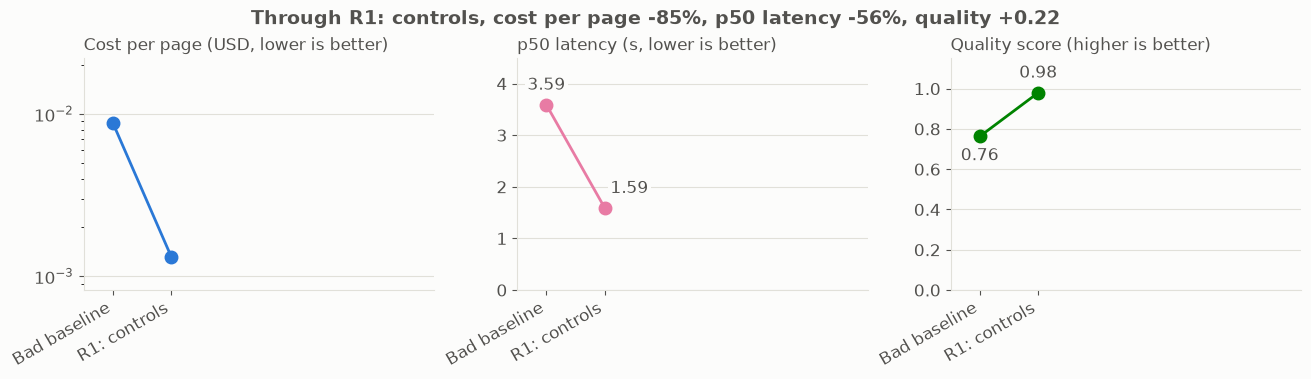

In [16]:
display(before_after(summary, BASELINE, CONTROLS).style.hide(axis="index"))
print(gate(traces, CONTROLS))
display(plot_progress(summary, upto_variant=CONTROLS))

## Round 2: model routing

**Lever:** `gpt-6-luna` triages; only risky pages go to `gpt-6.1-terra`.

**Watch:** the cheapest round so far, but it misses one required escalation.

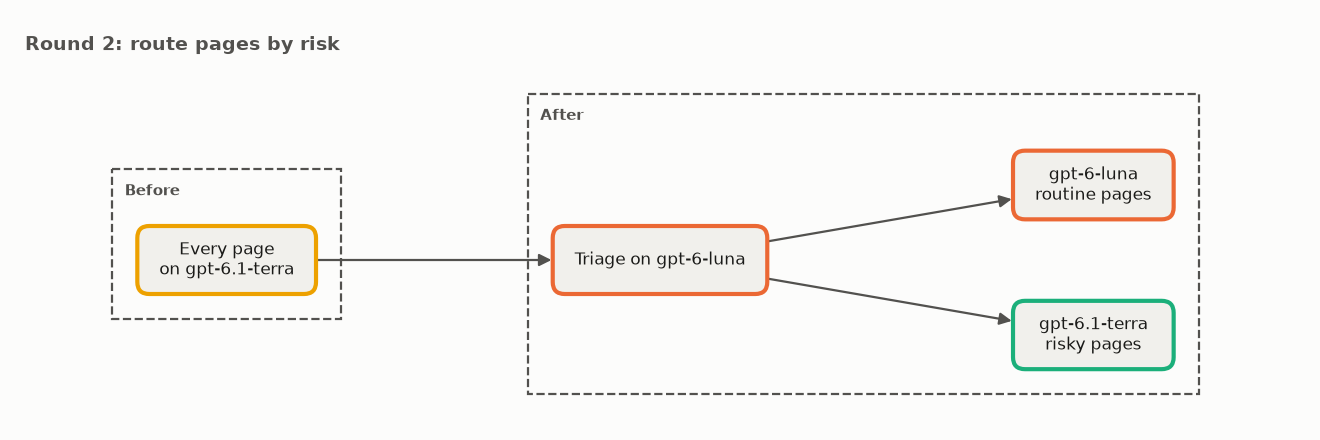

In [17]:
draw_diagram("round2")

In [18]:
display(request_diff(CONTROLS, ROUTING, LOW_PAGE).style.hide(axis="index"))

setting,before,after
model,gpt-6.1-terra,gpt-6-luna


metric,before,after
quality,0.98,0.97
privileged leaks,0,0
PII leaks,0,0
escalation rate,33%,30%
tool calls per page,0.8,0.8
sync tokens,"1,265","1,441"
p50 latency (s),1.59,1.38
model $/page,$0.00131,$0.00047
cost with attorney time $/page,$0.501,$0.450


Round 2: routing: ACCEPTED (guardrail pass 97%, floor 95%; failures: escalation_mismatch=1)


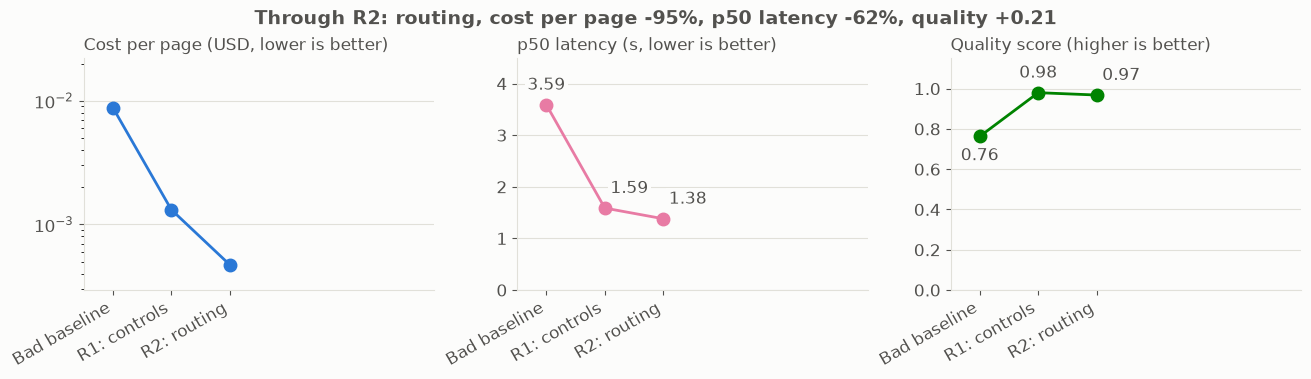

In [19]:
display(before_after(summary, CONTROLS, ROUTING).style.hide(axis="index"))
print(gate(traces, ROUTING))
display(plot_progress(summary, upto_variant=ROUTING))

## Round 3: replace the LLM with a decision model

**Lever:** one Decisions call answers three typed questions; plain code routes the page; `gpt-6.1-terra` gives a second opinion on the ambiguous band only.

**Watch:** model cost per page rises from Round 2, but the missed escalation is fixed and p50 latency halves.

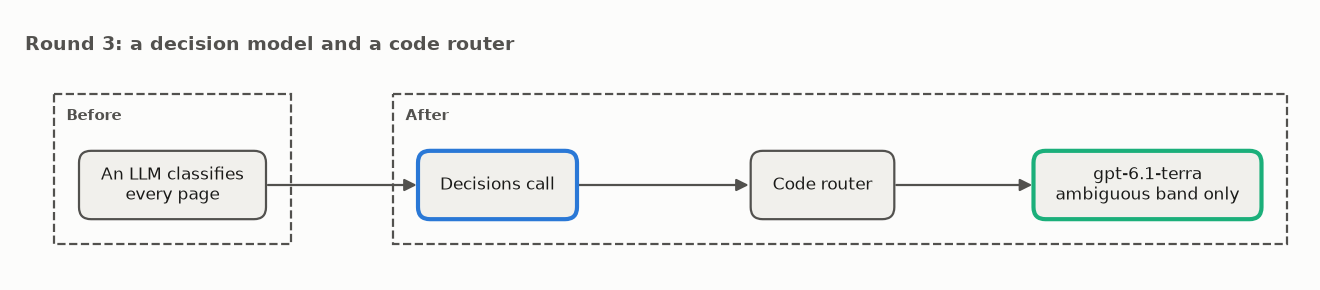

In [20]:
draw_diagram("round3")

In [21]:
display(request_diff(ROUTING, DECISION_MODEL, SAMPLE_PAGE).style.hide(axis="index"))

setting,before,after
model,gpt-6.1-terra,gpt-6-luna
reasoning,none,-
verbosity,low,-
structured_output,review_disposition,free text
max_output_tokens,600,-
tool_choice,"{""type"": ""allowed_tools"", ""mode"": ""auto"", ""tools"": [{""type"": ""function"", ""name"": ""lookup_custodian""}, {""type"": ""function"", ""name"": ""escalate_to_attorney""}]}",-
tools,"apply_redactions, check_prior_production, escalate_to_attorney, lookup_custodian, lookup_protocol",-
questions,-,"responsive, privileged, contains_pii"
instructions_chars,841,0
input_chars,416,5566


### Three typed questions, one call

In [22]:
from doc_review_opt.agent.classifiers.decisions import QUESTIONS, DecisionsClassifier
from doc_review_opt.agent.routing import decide

questions = pd.DataFrame(
    {"name": q["name"], "type": q["type"], "instructions": q["instructions"][:90] + ("…" if len(q["instructions"]) > 90 else "")}
    for q in QUESTIONS
)
display(questions.style.hide(axis="index"))

name,type,instructions
responsive,score,How relevant is this page to the matter described in the review protocol?
privileged,predicate,"Was this page written by or to a lawyer, or does it convey a lawyer's legal advice? Answer…"
contains_pii,predicate,"Does this page contain personal information such as contact details, account numbers, or h…"


In [23]:
from doc_review_opt.experiment.live import BudgetedClassifier
from doc_review_opt.experiment.simulation import SimulatedTypedClassifier
from doc_review_opt.fixtures import PROTOCOL

if RUN_LIVE_API_CALLS:
    classifier = BudgetedClassifier(DecisionsClassifier(client), budget)
else:
    classifier = SimulatedTypedClassifier("decisions")
result = await classifier.classify(SAMPLE_PAGE, PROTOCOL)

In [24]:
mode = "live" if RUN_LIVE_API_CALLS else "simulated"
print(f"{SAMPLE_PAGE.doc_id} ({mode}): {result.latency_s:.2f}s, ${result.cost_usd:.5f}")
if result.error:
    print(result.error)
else:
    shown = (("responsive score (0 to 2)", "responsive", "score"), ("privileged probability", "privileged", "probability"), ("contains-PII probability", "contains_pii", "probability"))
    for label, name, field in shown:
        value = getattr(result.answers.get(name), field, None)
        print(f"{label}: {'refused' if value is None else f'{value:.2f}'}")
decision = decide(result, CALIBRATED_POLICY)
print(f"route -> {decision.route} ({decision.reason})")

ARC-000284 (simulated): 0.13s, $0.00017
responsive score (0 to 2): 1.86
privileged probability: 0.90
contains-PII probability: 0.04
route -> attorney_review (privilege_above_threshold)


### The router is plain code: readable, testable, auditable

In [25]:
import inspect

print(inspect.getsource(decide))

def decide(
    result: ClassifierResult, policy: RoutingPolicy = DEFAULT_POLICY
) -> RouteDecision:
    if result.error is not None:
        return RouteDecision("attorney_review", "classifier_error")
    if any(isinstance(a, RefusalAnswer) for a in result.answers.values()):
        return RouteDecision("attorney_review", "missing_or_refused_answer")
    if result.agent_disposition is not None:
        return _route_agent(result.agent_disposition, result, policy)
    typed = _typed_answers(result)
    if typed is None:
        return RouteDecision("attorney_review", "missing_or_refused_answer")
    responsive, privileged, pii = typed
    if privileged.probability > policy.privilege_escalation:
        return RouteDecision("attorney_review", "privilege_above_threshold")
    if responsive.score < policy.not_responsive:
        return RouteDecision("withhold", "not_responsive")
    if responsive.score < policy.responsive:
        return RouteDecision("attorney_review", "ambiguous_respons

A refusal or an error never produces a page. It fails safe to an attorney.

In [26]:
from doc_review_opt.agent.classifiers.decisions import DECISIONS_MODEL
from doc_review_opt.models import ClassifierResult, RefusalAnswer

refused = ClassifierResult(
    engine="decisions",
    model=DECISIONS_MODEL,
    answers={"privileged": RefusalAnswer(name="privileged")},
)
print(decide(refused))

RouteDecision(route='attorney_review', reason='missing_or_refused_answer')


metric,before,after
quality,0.97,0.98
privileged leaks,0,0
PII leaks,0,0
escalation rate,30%,33%
tool calls per page,0.8,0.1
sync tokens,"1,441","2,381"
p50 latency (s),1.38,0.68
model $/page,$0.00047,$0.00070
cost with attorney time $/page,$0.450,$0.501


Round 3: decision model: ACCEPTED (guardrail pass 100%, floor 95%; failures: none)


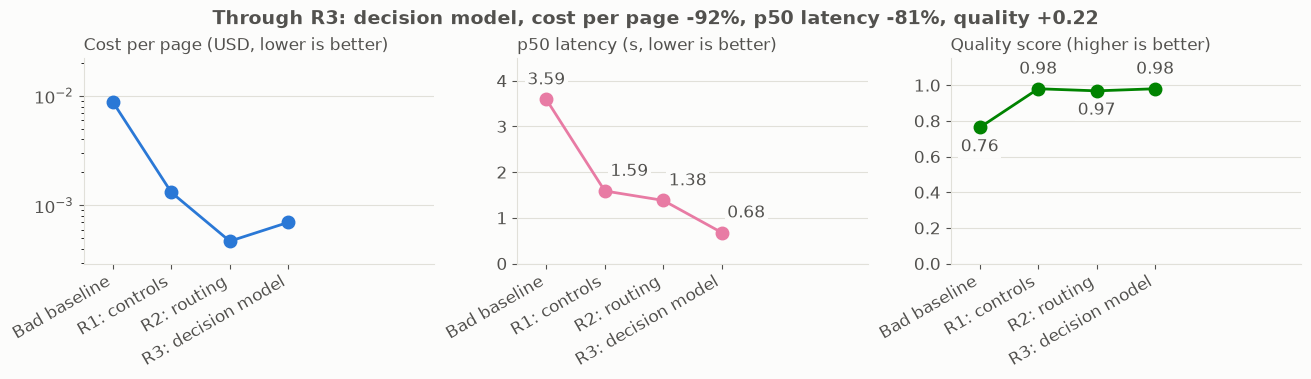

In [27]:
display(before_after(summary, ROUTING, DECISION_MODEL).style.hide(axis="index"))
print(gate(traces, DECISION_MODEL))
display(plot_progress(summary, upto_variant=DECISION_MODEL))

## LLM vs Decisions: the tradeoffs

Same three questions, four engines, 30 pages (simulated, calibrated thresholds).

In [28]:
def show_engines(table):
    view = table[["label", "accuracy_vs_labels", "cost_per_page_usd", "p50_latency_s", "escalation_rate", "privileged_leaks"]]
    view = view.rename(columns={"label": "Engine", "accuracy_vs_labels": "Accuracy", "cost_per_page_usd": "$ / page", "p50_latency_s": "p50 (s)", "escalation_rate": "To attorney", "privileged_leaks": "Privileged leaks"})
    formats = {"Accuracy": "{:.0%}", "$ / page": "${:.5f}", "p50 (s)": "{:.2f}", "To attorney": "{:.0%}"}
    display(view.style.format(formats).hide(axis="index"))

Engine,Accuracy,$ / page,p50 (s),To attorney,Privileged leaks
Decisions (gpt-6-luna),83%,$0.00018,0.13,50%,0
LLM probabilities (gpt-6-luna),80%,$0.00021,0.81,50%,0
LLM probabilities (gpt-6.1-terra),97%,$0.00203,1.18,33%,0
Agent (gpt-6.1-terra),100%,$0.00131,1.59,33%,0


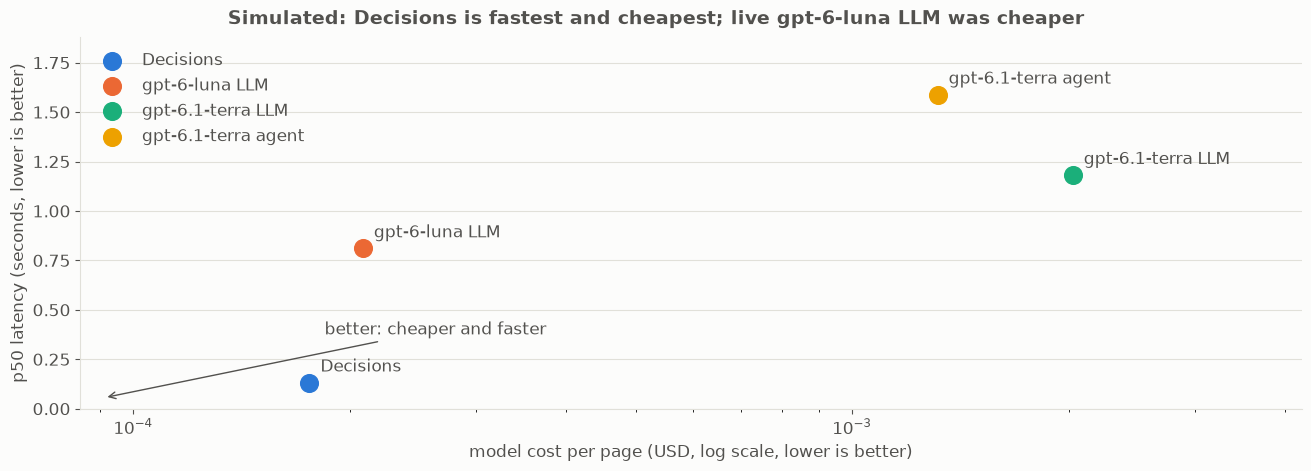

In [29]:
from doc_review_opt.experiment.tradeoffs import engine_comparison_table, plot_engine_tradeoff, simulate_engine_comparison

engine_runs = await simulate_engine_comparison(policy=CALIBRATED_POLICY)
engines = engine_comparison_table(engine_runs)
show_engines(engines)
display(plot_engine_tradeoff(engines))

**Read it:** Decisions alone is the fastest and cheapest, but it sends more pages to an attorney (50% vs 33%). That is why Round 3 adds the `gpt-6.1-terra` second opinion on the ambiguous band only.

### Probabilities are a dial

Move the privilege threshold. Decisions never leaks a privileged page; the LLMs' self-reported probabilities start leaking.

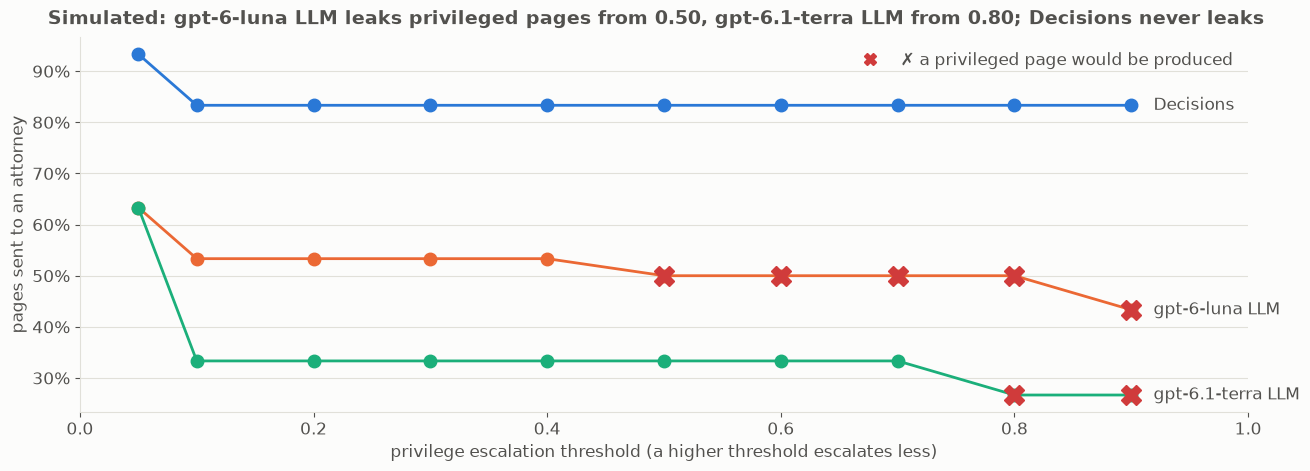

In [30]:
from doc_review_opt.experiment.tradeoffs import plot_threshold_sweep, threshold_sweep

display(plot_threshold_sweep(threshold_sweep(await simulate_engine_comparison(), EVAL_SET)))

### What Decisions can't do

Write text, extract spans or call tools. Each step gets the engine it needs:

In [31]:
from doc_review_opt.experiment.tradeoffs import STEP_MATRIX

display(pd.DataFrame(STEP_MATRIX).style.hide(axis="index"))

step,fits,why
Responsiveness rubric,Decisions,"A fixed 0-2 rubric is a typed score: one cheap call, no text to write."
Privilege predicate,Decisions,A yes/no with a probability feeds a low escalation threshold; the cascade sends the ambiguous band to a stronger model.
PII presence,Decisions,Deciding whether personal data is present is a predicate; finding the spans is not (Decisions cannot extract to your own schema).
Near-duplicate check,Code,An index lookup is deterministic and free; no model should do it.
Escalation gate,Code,Thresholds over typed answers are plain code you can test and audit.
Redaction rewrite,LLM,Writing the page with spans replaced is generation; Decisions only answers questions.
Privilege-log drafting,LLM,A log entry is free text with an explanation; Decisions cannot write one.
QA tags,LLM,Tags and notes are generated text; batch them off the page path.


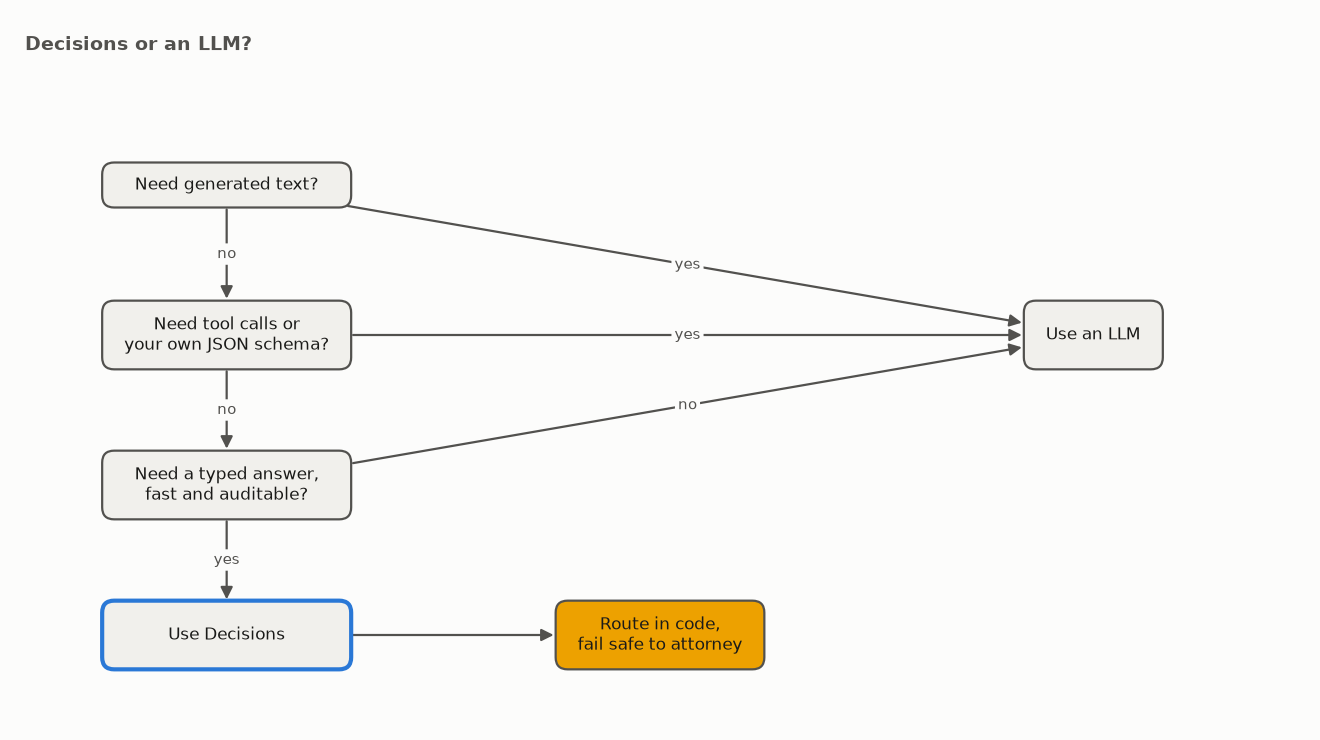

In [32]:
draw_diagram("decisions_or_llm")

## Round 4: prompt caching

**Lever:** the stable protocol prefix goes first, with one cache key per matter.

**Watch:** cache writes cost 1.25x, so caching pays only at volume.

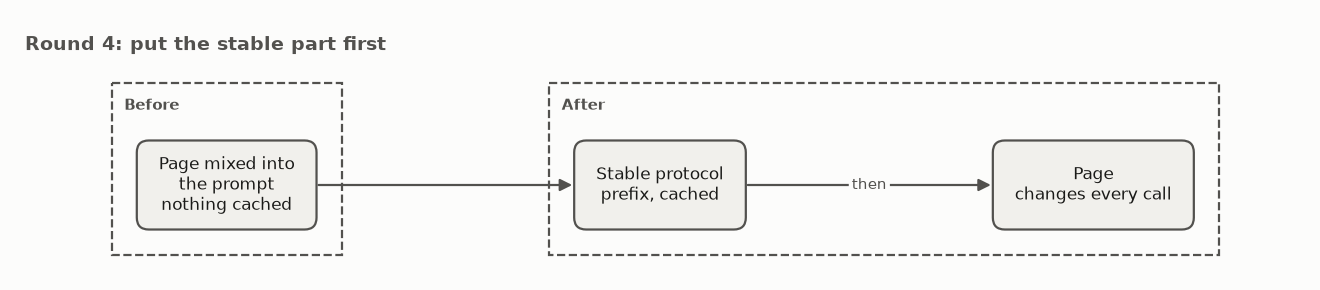

In [33]:
draw_diagram("round4")

In [34]:
display(request_diff(DECISION_MODEL, CACHING, SAMPLE_PAGE).style.hide(axis="index"))

setting,before,after
prompt_cache_key,-,matter-24-CV-118 (Hollis v. Arcadia Freight)


metric,before,after
quality,0.98,0.98
privileged leaks,0,0
PII leaks,0,0
escalation rate,33%,33%
tool calls per page,0.1,0.1
sync tokens,"2,381","2,605"
p50 latency (s),0.68,0.66
model $/page,$0.00070,$0.00060
cost with attorney time $/page,$0.501,$0.501


Round 4: caching: ACCEPTED (guardrail pass 100%, floor 95%; failures: none)


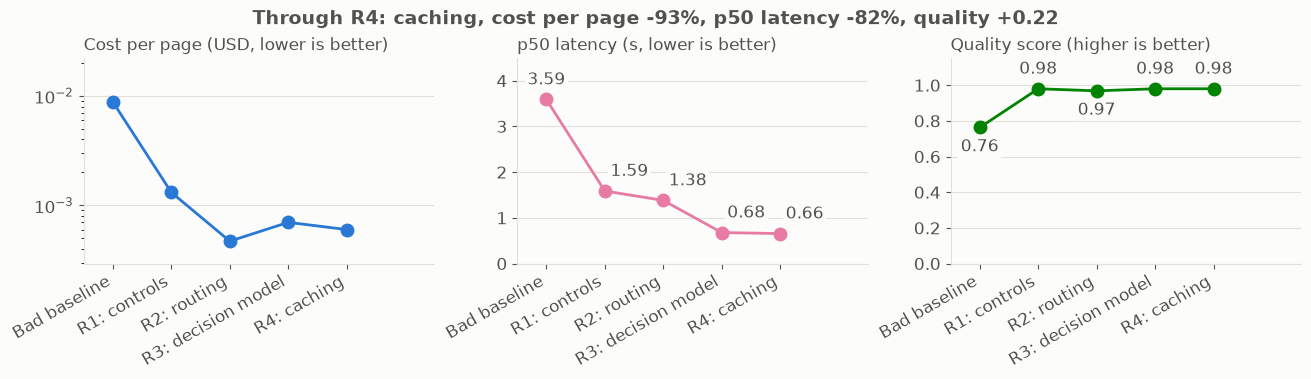

In [35]:
display(before_after(summary, DECISION_MODEL, CACHING).style.hide(axis="index"))
print(gate(traces, CACHING))
display(plot_progress(summary, upto_variant=CACHING))

## Round 5: split the workflow

**Lever:** privilege log, QA and tags leave the page path and go to Batch at 50% off.

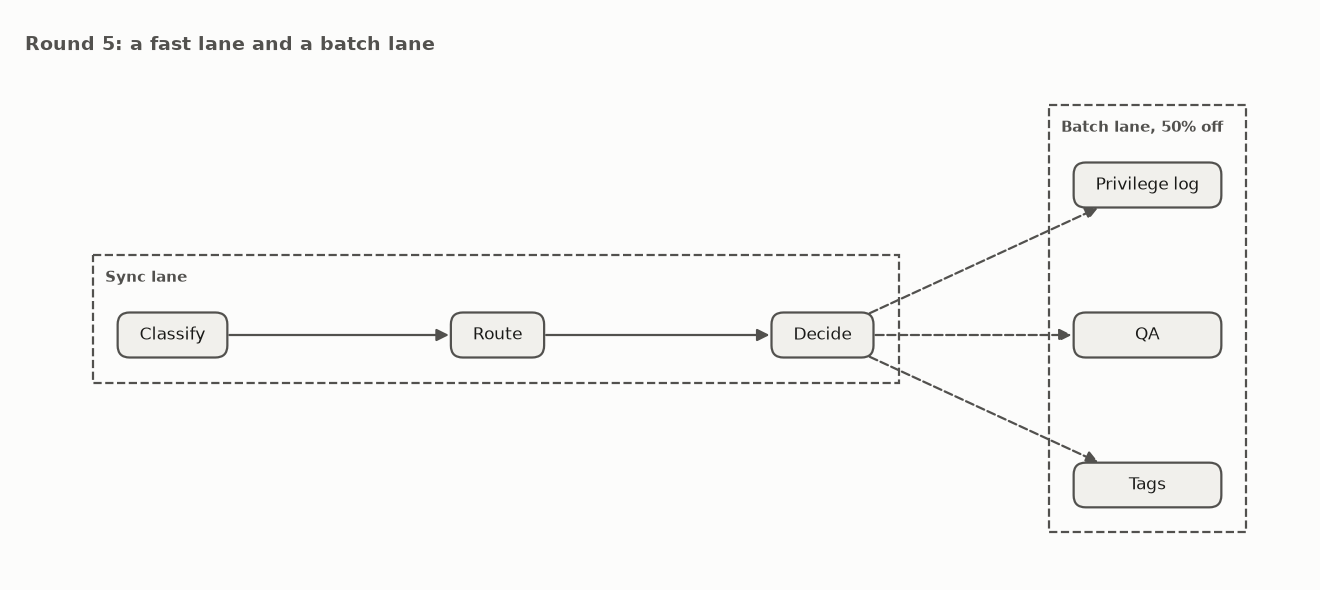

In [36]:
draw_diagram("round5")

metric,before,after
quality,0.98,0.98
privileged leaks,0,0
PII leaks,0,0
escalation rate,33%,33%
tool calls per page,0.1,0.1
sync tokens,"2,605","2,267"
p50 latency (s),0.66,0.11
model $/page,$0.00060,$0.00060
cost with attorney time $/page,$0.501,$0.501


Round 5: split workflow: ACCEPTED (guardrail pass 100%, floor 95%; failures: none)


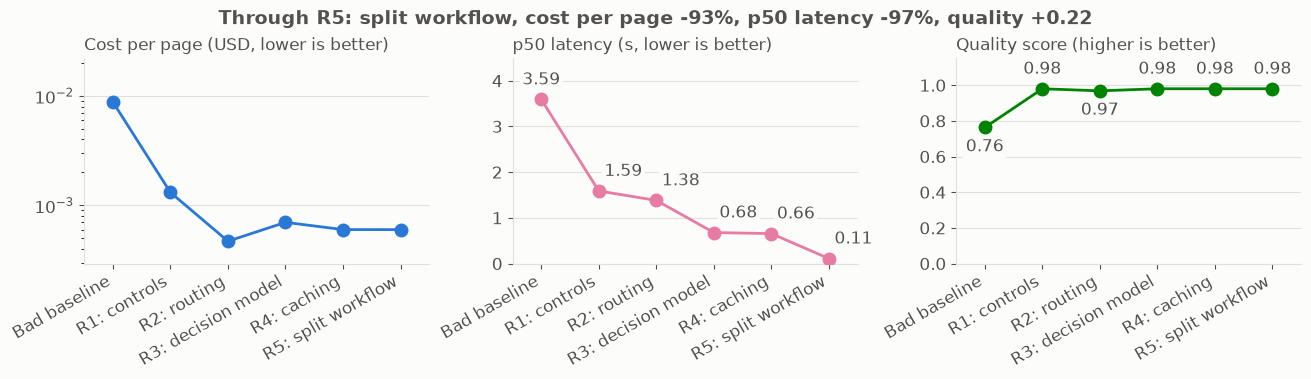

In [37]:
display(before_after(summary, CACHING, SPLIT).style.hide(axis="index"))
print(gate(traces, SPLIT))
display(plot_progress(summary, upto_variant=SPLIT))

## Results: the climb

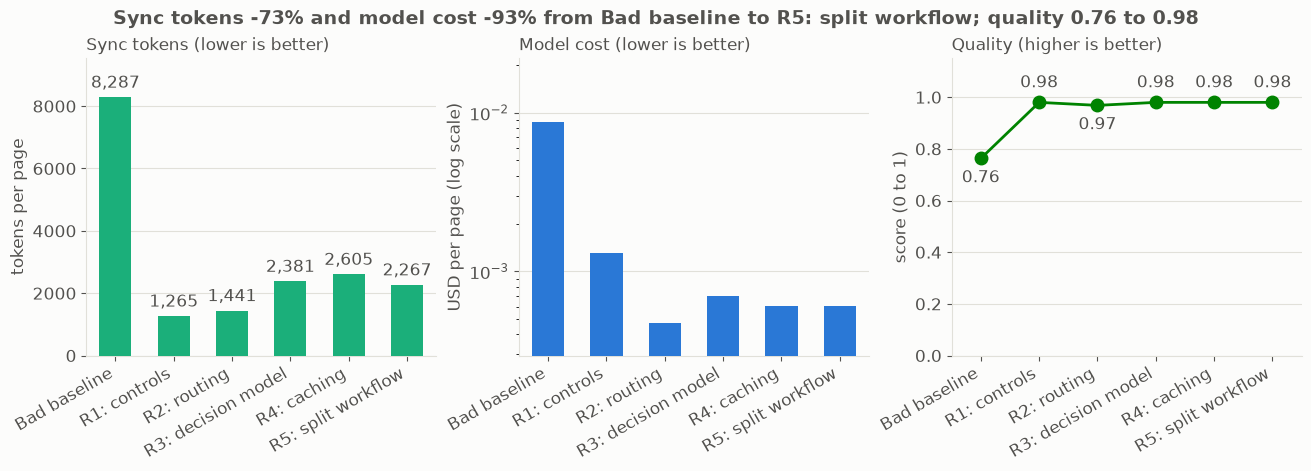

In [38]:
from doc_review_opt.reporting.reporting import plot_quality_gate, plot_round_chart
from doc_review_opt.reporting.walkthrough import gate_table

display(plot_round_chart(summary))

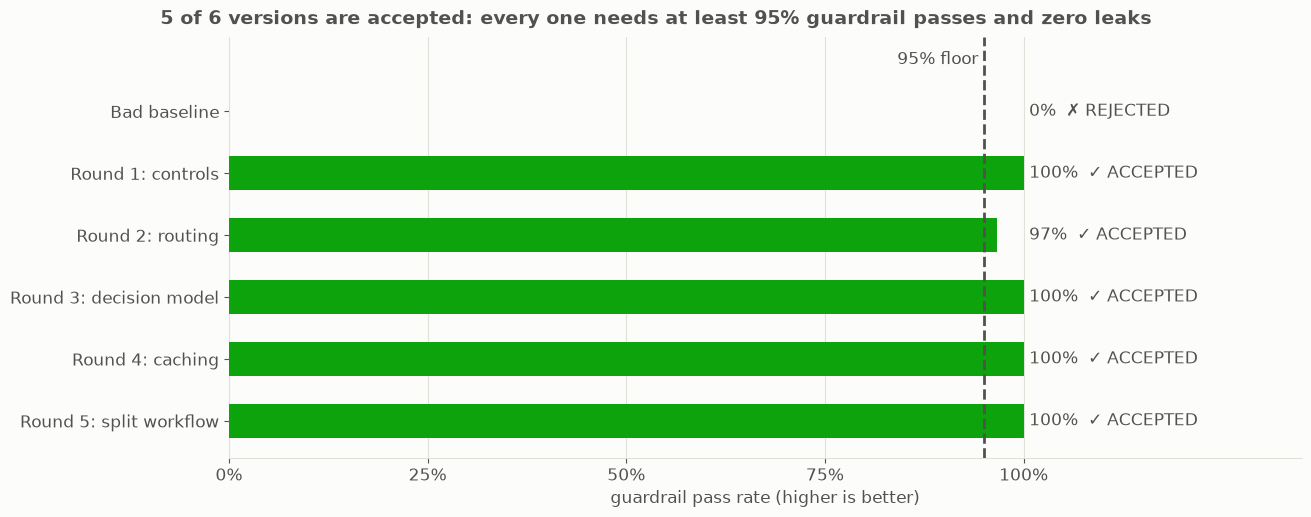

In [39]:
floor = get_settings().quality.guardrail_pass_floor
display(plot_quality_gate(gate_table(traces, VARIANT_ORDER), floor))

## Live reality check

Real APIs, 6 pages, 2026-11-18, $0.18 total.

| Engine | Accuracy | $ / page | p50 |
|---|---|---|---|
| **Decisions** | 100% | $0.00019 | **0.38s** |
| `gpt-6-luna` LLM | 100% | **$0.00011** | 2.26s |
| `gpt-6.1-terra` LLM | 100% | $0.00073 | 3.03s |
| `gpt-6.1-terra` agent | 100% | $0.00118 | 2.33s |

Decisions is **about 6x faster** than `gpt-6-luna` and **4 to 6x cheaper** than `gpt-6.1-terra`, but **1.7x pricier** than `gpt-6-luna`.

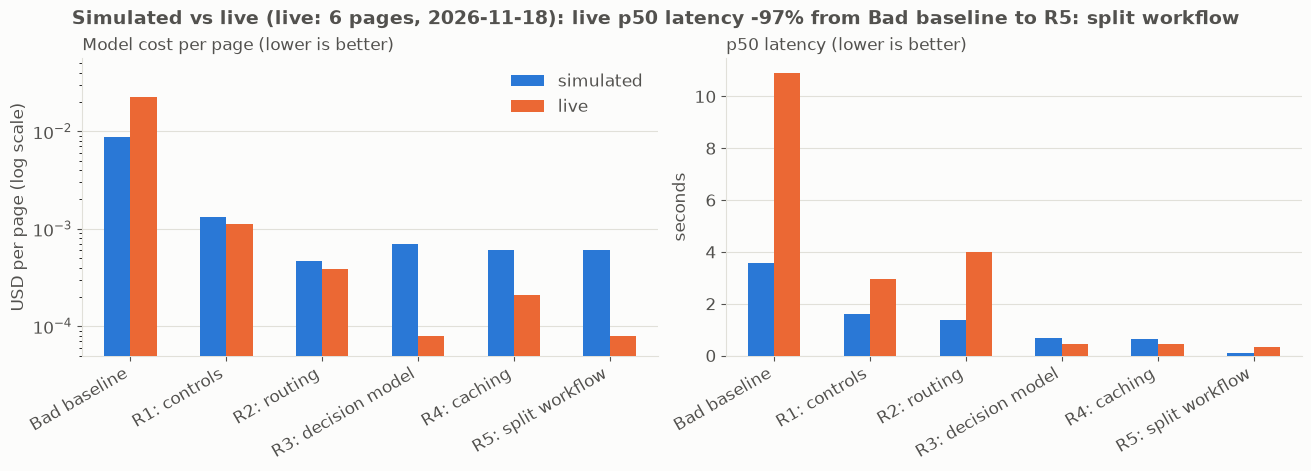

In [40]:
from doc_review_opt.reporting.reporting import plot_sim_vs_live, recorded_live_note, recorded_live_summary

display(plot_sim_vs_live(summary, recorded_live_summary(), recorded_live_note()))

Optional, on stage: rerun the engine comparison on the real APIs. It takes about a minute, costs a few cents and sends LangSmith traces.

In [41]:
from itertools import zip_longest

from doc_review_opt.experiment.live import LIVE_PAGE_LIMIT
from doc_review_opt.experiment.tradeoffs import live_engine_comparison

by_route = {}
for page in EVAL_SET:
    by_route.setdefault(page.labels.expected_route, []).append(page)
live_pages = [p for group in zip_longest(*by_route.values()) for p in group if p]
live_pages = live_pages[:LIVE_PAGE_LIMIT]

In [42]:
live_runs = {}
if RUN_LIVE_API_CALLS:
    live_runs = await live_engine_comparison(live_pages, client=client, budget=budget)
if live_runs:
    show_engines(engine_comparison_table(live_runs))
    print("\n".join(f"{n}: {r.trace_url or 'LangSmith tracing is off'}" for n, r in live_runs.items()))
    print(f"Spend: ${budget.total_usd:.4f} of ${budget.limit_usd:.2f}")
elif RUN_LIVE_API_CALLS:
    print(f"Stopped by the budget: ${budget.total_usd:.2f} of ${budget.limit_usd:.2f}")
else:
    print("Offline. Set RUN_LIVE_API_CALLS=true to rerun this on the real APIs.")

Offline. Set RUN_LIVE_API_CALLS=true to rerun this on the real APIs.


## Takeaways

1. **Measure first.** A labelled eval set and hard gates before any tuning.
2. **Cut waste before changing models.** Controls gave the biggest drop.
3. **Cheapest is not best.** Every round must pass the quality gate.
4. **Typed decision? Try Decisions with a code router.** Fast, calibratable, auditable.
5. **Need text, tools or extraction? Keep an LLM**, the smallest that holds quality.
6. **Re-measure live.** Live, Decisions was fastest, but the smallest LLM was cheaper.

## References

Last verified: November 18, 2026.

- [Optimizing agents for cost and quality](https://github.com/openai/openai-cookbook/tree/main/examples/agent_optimization) (OpenAI Cookbook)
- [Document review agent](https://gist.github.com/sydney-runkle/a632ba4ea0b2b72501dfa4b6ab2a7d8a) (gist by Sydney Runkle)
- [Decisions API guide](https://developers.openai.com/api/docs/guides/decisions)
- [Pricing](https://developers.openai.com/api/docs/pricing)
- LangGraph [`Send`](https://langchain-ai.github.io/langgraph/concepts/low_level/#send) and [`interrupt`](https://langchain-ai.github.io/langgraph/concepts/human_in_the_loop/)